In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

In [3]:
hour_df = pd.read_csv("../data/raw/hour.csv")
day_df = pd.read_csv("../data/raw/day.csv")

print("Hourly dataset shape:", hour_df.shape)
print("Daily dataset shape:", day_df.shape)

display(hour_df.head())
display(day_df.head())

Hourly dataset shape: (17379, 17)
Daily dataset shape: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
print("Hourly dataset information:")
hour_df.info()

print("\nMissing values:")
print(hour_df.isnull().sum())

print("\nDaily dataset information:")
day_df.info()

print("\nSummary statistics:")
display(hour_df.describe())

Hourly dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB

Missing values:
instant       0
dte

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


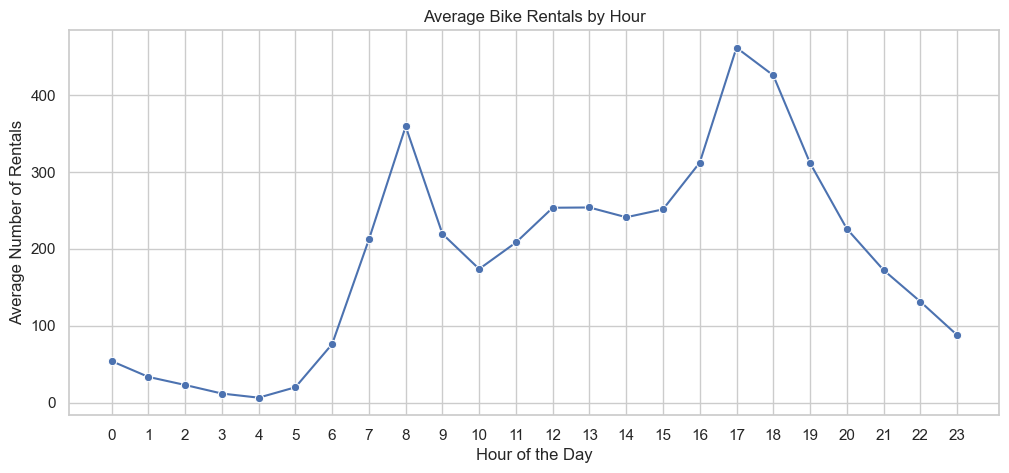

In [5]:
hourly_demand = hour_df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=hourly_demand.index,
    y=hourly_demand.values,
    marker="o"
)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(True)
plt.show()

In [6]:
peak_hour = hourly_demand.idxmax()
low_hour = hourly_demand.idxmin()

print("Peak demand hour:", peak_hour)
print("Average rentals at peak:", round(hourly_demand.max(), 2))

print("Lowest demand hour:", low_hour)
print("Average rentals at low:", round(hourly_demand.min(), 2))

Peak demand hour: 17
Average rentals at peak: 461.45
Lowest demand hour: 4
Average rentals at low: 6.35


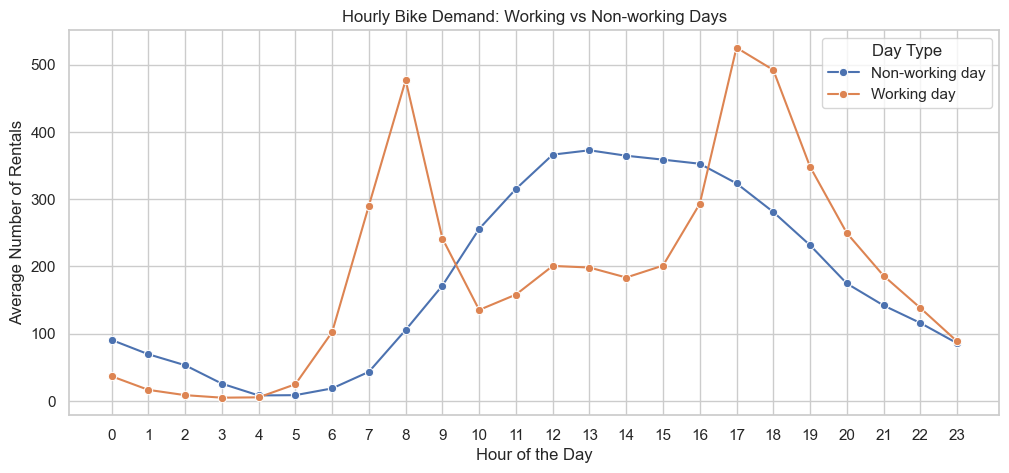

In [7]:
working_comparison = (
    hour_df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

working_comparison["Day Type"] = working_comparison[
    "workingday"
].map({
    0: "Non-working day",
    1: "Working day"
})

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=working_comparison,
    x="hr",
    y="cnt",
    hue="Day Type",
    marker="o"
)

plt.title("Hourly Bike Demand: Working vs Non-working Days")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.legend(title="Day Type")
plt.show()

In [8]:
comparison_summary = hour_df.groupby("workingday")["cnt"].agg(
    ["mean", "median", "sum", "count"]
)

comparison_summary.index = comparison_summary.index.map({
    0: "Non-working day",
    1: "Working day"
})

comparison_summary.columns = [
    "Average Rentals",
    "Median Rentals",
    "Total Rentals",
    "Hourly Records"
]

display(comparison_summary.round(2))

,Average Rentals,Median Rentals,Total Rentals,Hourly Records
workingday,,,,
Non-working day,181.41,119.0,1000269,5514
Working day,193.21,151.0,2292410,11865


In [9]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

day_df["year"] = day_df["dteday"].dt.year
day_df["month"] = day_df["dteday"].dt.month

print("Date range:")
print(day_df["dteday"].min(), "to", day_df["dteday"].max())

Date range:
2011-01-01 00:00:00 to 2012-12-31 00:00:00


Yearly rental summary:


,mean,sum
year,,
2011,3405.76,1243103
2012,5599.93,2049576


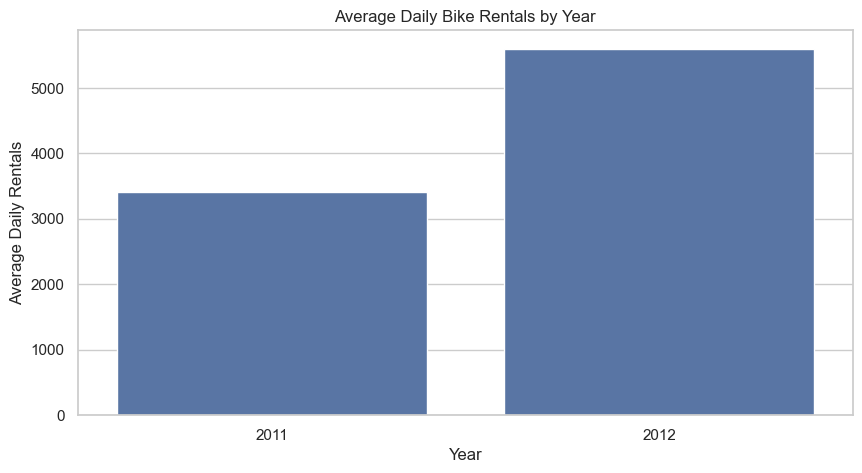

In [10]:
yearly_demand = day_df.groupby("year")["cnt"].agg(
    ["mean", "sum"]
)

print("Yearly rental summary:")
display(yearly_demand.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=day_df,
    x="year",
    y="cnt",
    estimator="mean",
    errorbar=None
)

plt.title("Average Daily Bike Rentals by Year")
plt.xlabel("Year")
plt.ylabel("Average Daily Rentals")
plt.show()

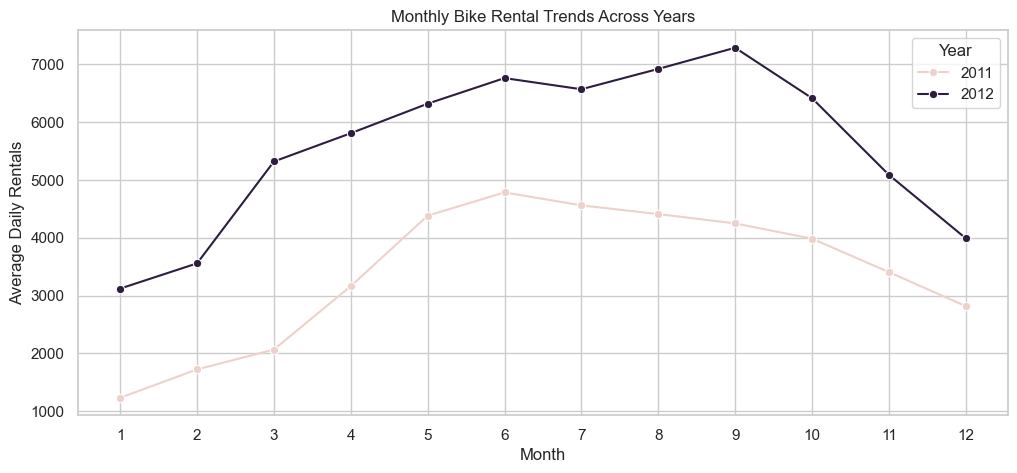

In [11]:
monthly_demand = (
    day_df.groupby(["year", "month"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_demand,
    x="month",
    y="cnt",
    hue="year",
    marker="o"
)

plt.title("Monthly Bike Rental Trends Across Years")
plt.xlabel("Month")
plt.ylabel("Average Daily Rentals")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.show()

## EDA Findings — Hourly Bike-Rental Demand for Fleet Rebalancing

### 1. Hourly Patterns
- Identified the peak-demand hour using average hourly rental counts.
- Identified the lowest-demand hour.
- Observed daily demand patterns to understand when additional bikes may be needed.

### 2. Working Day Comparison
- Compared hourly rental demand between working days and non-working days.
- Examined differences in peak hours and average rental counts.
- Identified potential commuting-related demand patterns.

### 3. Yearly Trends
- Compared average daily bike rentals across years.
- Analyzed monthly demand patterns to identify seasonal variations.
- Examined changes in demand over time.

### Conclusion
The EDA provides an initial understanding of hourly, weekly, and seasonal demand patterns. These findings can help guide future fleet-rebalancing decisions by identifying periods of high demand and times when bikes may be underutilized.

## Data Validation and Missing-Hour Analysis

The dataset contains no ordinary null values or duplicate rows. However, this does not guarantee a complete hourly time series because an entire hourly observation can be absent without creating a `NaN`.

To check temporal completeness, the `dteday` and `hr` columns are combined into an hourly timestamp and compared with the complete sequence of expected hourly timestamps between the first and last observations.

Reusable validation functions for these checks are implemented in `src/validation.py`.

In [12]:
import sys
from pathlib import Path

# Make the repository root importable when this notebook is run
# from inside the notebooks/ directory.
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.validation import (
    find_missing_hours,
    find_missing_hour_blocks,
    validate_target_identity,
)

missing_hours = find_missing_hours(hour_df)
missing_blocks = find_missing_hour_blocks(hour_df)

print(f"Missing hourly timestamps: {len(missing_hours)}")
print(f"Number of missing blocks: {len(missing_blocks)}")

display(missing_blocks.head(10))

Missing hourly timestamps: 165
Number of missing blocks: 75


,start,end,hours_missing
0,2012-10-29 01:00:00,2012-10-30 12:00:00,36
1,2011-01-26 18:00:00,2011-01-27 15:00:00,22
2,2011-08-27 18:00:00,2011-08-28 06:00:00,13
3,2011-01-18 00:00:00,2011-01-18 11:00:00,12
4,2011-02-22 00:00:00,2011-02-22 05:00:00,6
5,2011-01-26 03:00:00,2011-01-26 04:00:00,2
6,2011-03-10 03:00:00,2011-03-10 04:00:00,2
7,2011-01-12 03:00:00,2011-01-12 04:00:00,2
8,2011-02-11 03:00:00,2011-02-11 04:00:00,2
9,2011-01-11 03:00:00,2011-01-11 04:00:00,2


### Missing-Hour Findings and Handling Decision

The complete hourly sequence contains **165 timestamps that are absent from `hour.csv`**, grouped into **75 separate missing blocks**.

The gaps are not limited to isolated low-demand hours. Several long consecutive periods are absent, including a **36-hour block from 2012-10-29 01:00 to 2012-10-30 12:00**, a 22-hour block in January 2011, and a 13-hour block in August 2011. Therefore, it would be unsafe to assume that every absent row represents exactly zero rentals.

We retain the original observed rows for modelling rather than automatically inserting the missing timestamps. Adding such rows would require assigning not only `cnt = 0`, but also unsupported values for predictors such as weather conditions, temperature, humidity, and windspeed.

Thus, the gaps are **detected, quantified, and documented, but not imputed**.

In [13]:
# Verify the exact relationship between the target and its components.
target_identity_valid = validate_target_identity(hour_df)


=== TARGET LEAKAGE VALIDATION ===
PASS: cnt equals casual + registered for every row.


### Target Leakage Check

The validation confirms that `cnt = casual + registered` for every hourly observation. Therefore, `casual` and `registered` directly reveal the target and will **not** be included as predictor variables when modelling `cnt`.

Including either of these target components would introduce target leakage and produce unrealistically optimistic model performance.

### Normalized Weather Variables

The variables `temp`, `atemp`, `hum`, and `windspeed` are already normalized in the supplied UCI dataset. They are therefore retained in their donor-provided normalized form for this project and are **not interpreted directly as physical units** such as degrees Celsius or raw wind speed.

The reusable validation code in `src/validation.py` checks that these variables remain within the expected normalized range `[0, 1]`.

 Chronological Train/Test Split and Linear Regression Baseline

 Objective

The objective of this experiment is to establish a baseline machine learning model for predicting hourly bike-rental demand. The hourly dataset is divided chronologically into training and testing sets to preserve the temporal order of observations.

A Linear Regression model is trained on historical observations and evaluated on later observations using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).


In [14]:
import pandas as pd
import numpy as np

# Work on a copy of the validated hourly dataset
model_df = hour_df.copy()

# Construct a timestamp from the date and hour columns
model_df["datetime"] = (
    pd.to_datetime(model_df["dteday"]) +
    pd.to_timedelta(model_df["hr"], unit="h")
)

# Sort observations chronologically
model_df = model_df.sort_values("datetime").reset_index(drop=True)

# Display the dataset information
print("Dataset shape:", model_df.shape)
print("First timestamp:", model_df["datetime"].min())
print("Last timestamp:", model_df["datetime"].max())

model_df[["datetime", "hr", "cnt"]].head()

Dataset shape: (17379, 18)
First timestamp: 2011-01-01 00:00:00
Last timestamp: 2012-12-31 23:00:00


,datetime,hr,cnt
0,2011-01-01 00:00:00,0,16
1,2011-01-01 01:00:00,1,40
2,2011-01-01 02:00:00,2,32
3,2011-01-01 03:00:00,3,13
4,2011-01-01 04:00:00,4,1


In [15]:
from sklearn.model_selection import train_test_split

# Define the target variable
target = "cnt"

# Select features and exclude target leakage columns
drop_columns = [
    "cnt",
    "casual",
    "registered",
    "datetime",
    "dteday",
    "instant"
]

X = model_df.drop(
    columns=[col for col in drop_columns if col in model_df.columns]
)

y = model_df[target]

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(model_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display split information
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training percentage:", round(len(X_train) / len(model_df) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(model_df) * 100, 2), "%")

print("\nLast training timestamp:",
      model_df["datetime"].iloc[split_index - 1])

print("First testing timestamp:",
      model_df["datetime"].iloc[split_index])

Training samples: 13903
Testing samples: 3476
Training percentage: 80.0 %
Testing percentage: 20.0 %

Last training timestamp: 2012-08-07 11:00:00
First testing timestamp: 2012-08-07 12:00:00


In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Linear Regression model
lr_model = LinearRegression()

# Train the model using the training data
lr_model.fit(X_train, y_train)

# Predict bike-rental demand on the test data
y_pred = lr_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display results
print("LINEAR REGRESSION BASELINE RESULTS")
print("----------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

LINEAR REGRESSION BASELINE RESULTS
----------------------------------
MAE  : 138.29
RMSE : 183.28
R²   : 0.3090


Observation-
The Linear Regression model was trained using a chronological 80:20 train-test split to predict hourly bike-rental demand. The model achieved a Mean Absolute Error (MAE) of 138.29, a Root Mean Squared Error (RMSE) of 183.28, and an R² score of 0.3090. The results indicate that the baseline model captures some variation in rental demand but has limited predictive performance. Further improvements may be possible through feature engineering and regularized or nonlinear regression models.
